In [8]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

# Generate 1000 records
n_samples = 1000

# Generate columns
loan_ids = [f"LP{i:04d}" for i in range(1, n_samples + 1)]
ages = np.random.randint(21, 66, size=n_samples)
incomes = np.random.randint(20000, 150001, size=n_samples)
loan_amounts = np.random.randint(5000, 50001, size=n_samples)
credit_scores = np.random.randint(300, 851, size=n_samples)
debt_to_income = np.round(np.random.uniform(0.1, 0.6, size=n_samples), 2)

# Simple rule-based logic to determine loan approval (with some randomness)
# High credit score and low debt-to-income ratio increase approval chances
scores_norm = (credit_scores - 300) / 550
dti_norm = 1 - debt_to_income
prob_approve = 0.5 * scores_norm + 0.3 * dti_norm + 0.2 * np.random.rand(n_samples)
loan_status = np.where(prob_approve > 0.5, 'Approved', 'Rejected')

# Create DataFrame
df = pd.DataFrame({
    'Loan_ID': loan_ids,
    'Age': ages,
    'Annual_Income': incomes,
    'Loan_Amount': loan_amounts,
    'Credit_Score': credit_scores,
    'Debt_to_Income': debt_to_income,
    'Loan_Status': loan_status
})

# Save to CSV
df.to_csv('loan_details.csv', index=False)
print(f"Dataset successfully created with {df.shape[0]} rows and {df.shape[1]} columns.")
print(df.head())

Dataset successfully created with 1000 rows and 7 columns.
  Loan_ID  Age  Annual_Income  Loan_Amount  Credit_Score  Debt_to_Income  \
0  LP0001   59          43930        22175           725            0.46   
1  LP0002   49          20077        31385           846            0.53   
2  LP0003   35         125881        43158           601            0.24   
3  LP0004   63         145501        28019           648            0.50   
4  LP0005   28          40611        23639           348            0.20   

  Loan_Status  
0    Approved  
1    Approved  
2    Approved  
3    Rejected  
4    Rejected  


### Logistic Regression Model for Loan Approval Prediction
We will prepare our features, split the data into training and testing sets, normalize the numeric values, and train a Logistic Regression classifier.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load the dataset
data = pd.read_csv('loan_details.csv')

# Define features (X) and target (y)
# 'Loan_ID' is an identifier and won't be useful for prediction
X = data[['Age', 'Annual_Income', 'Loan_Amount', 'Credit_Score', 'Debt_to_Income']]
y = data['Loan_Status'].map({'Approved': 1, 'Rejected': 0}) # Encode target to binary

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling (important for Logistic Regression stability and performance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Model Accuracy: 0.9250

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.86      0.93      0.89        67
    Approved       0.96      0.92      0.94       133

    accuracy                           0.93       200
   macro avg       0.91      0.93      0.92       200
weighted avg       0.93      0.93      0.93       200



### Visualizing Bias and Variance via Learning Curves
Learning curves display the training score and validation score of an estimator for varying numbers of training samples. This allows us to see if the model has a high bias (both scores are low and close) or high variance (a large gap remains between the training and validation scores).

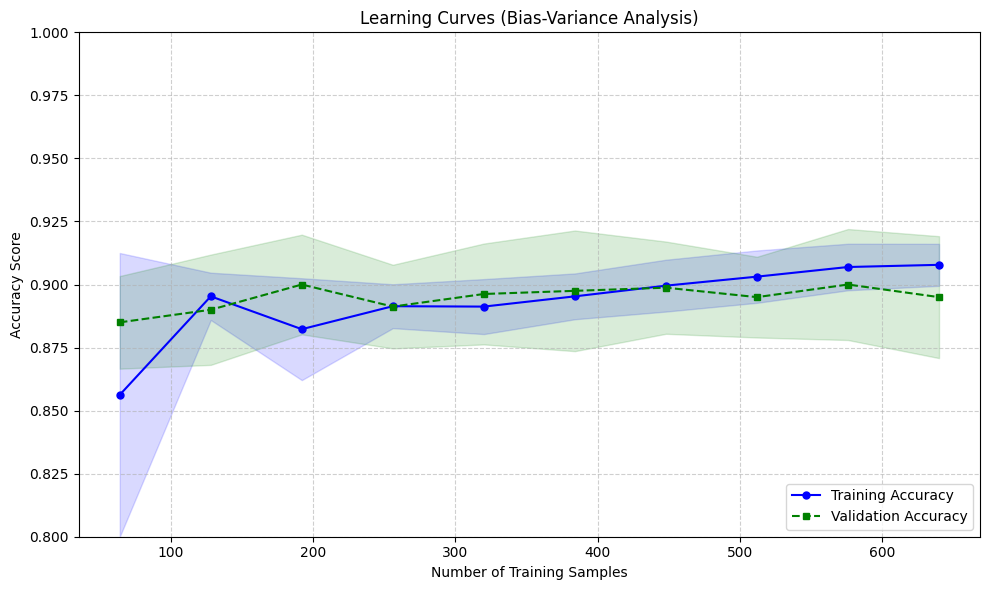

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Calculate learning curves
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Calculate mean and standard deviation for training and test scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot learning curves
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training Accuracy')
plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, color='green', linestyle='--', marker='s', markersize=5, label='Validation Accuracy')
plt.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

plt.grid(True, linestyle='--', alpha=0.6)
plt.xlabel('Number of Training Samples')
plt.ylabel('Accuracy Score')
plt.legend(loc='lower right')
plt.title('Learning Curves (Bias-Variance Analysis)')
plt.ylim([0.8, 1.0])
plt.tight_layout()
plt.show()

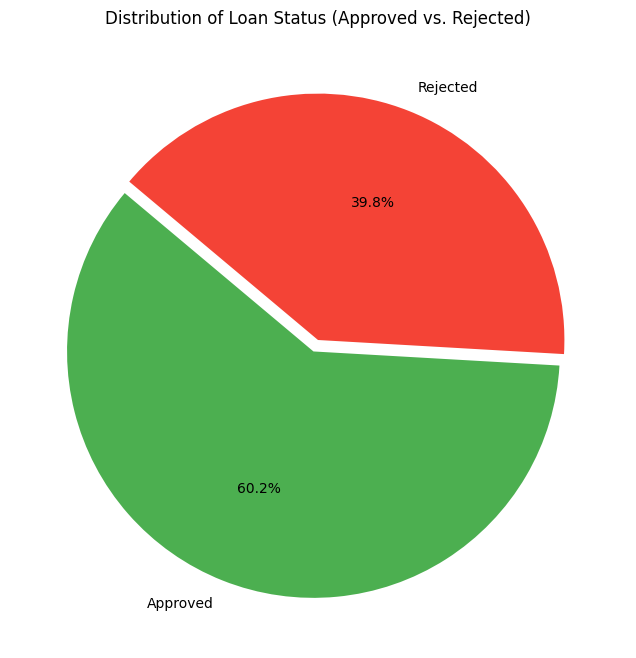

In [9]:
import matplotlib.pyplot as plt

# Count the occurrences of each loan status
status_counts = data['Loan_Status'].value_counts()

# Create a pie chart
plt.figure(figsize=(8, 8))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4CAF50', '#F44336'],
    explode=(0.05, 0)
)
plt.title('Distribution of Loan Status (Approved vs. Rejected)')
plt.show()

In [13]:
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
import numpy as np

def predict_loan_status(age, annual_income, loan_amount, credit_score, debt_to_income):
    # Prepare the input features as a DataFrame to match the training format
    input_data = pd.DataFrame([{
        'Age': age,
        'Annual_Income': annual_income,
        'Loan_Amount': loan_amount,
        'Credit_Score': credit_score,
        'Debt_to_Income': debt_to_income
    }])

    # Scale the inputs using the fitted scaler
    input_scaled = scaler.transform(input_data)

    # Get prediction and probabilities
    prediction = model.predict(input_scaled)[0]
    probability = model.predict_proba(input_scaled)[0]

    # Display results
    status = "Approved" if prediction == 1 else "Rejected"
    confidence = probability[prediction] * 100

    print("=" * 40)
    print("             PREDICTION RESULT             ")
    print("=" * 40)
    print(f"Loan Status Prediction: {status}")
    print(f"Confidence Probability: {confidence:.2f}%")
    print("=" * 40)

# Create interactive widgets
interact(
    predict_loan_status,
    age=widgets.IntSlider(min=21, max=100, step=1, value=35, description='Age:'),
    annual_income=widgets.IntSlider(min=10000, max=250000, step=1000, value=60000, description='Income ($):'),
    loan_amount=widgets.IntSlider(min=1000, max=100000, step=1000, value=25000, description='Loan ($):'),
    credit_score=widgets.IntSlider(min=300, max=850, step=5, value=700, description='Credit Score:'),
    debt_to_income=widgets.FloatSlider(min=0.0, max=1.0, step=0.01, value=0.35, description='DTI Ratio:')
);

interactive(children=(IntSlider(value=35, description='Age:', min=21), IntSlider(value=60000, description='Inc…